<a href="https://colab.research.google.com/github/yeugeneu/IAT360-CV-13-Cloud-Type-Classifier/blob/Dalena-hyperparameter-test/Cloud_type_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Preprocessing
We have to convert the dataset into that acceptable by YOLO.
- Heirarchy of folders should be the one accepted by YOLO
- Labels format should be object detection for YOLOv8
```
class x_center y_center width height
```

- Labels files should be .txt files with an object in the image per row

1. Make sure you download and extract the dataset [CloudDataset](https://app.roboflow.com/eugene-yu/cloud-qthye-mirzy/1) forked from [Roboflow Cloud Computer Vision Model dataset](https://universe.roboflow.com/ip2-kbjz5/cloud-qthye/browse?queryText=&pageSize=100&startingIndex=0&browseQuery=true)


2. Rename the folder to 'CloudDataset'

3. Below steps will guide you through converting the original dataset to the folder hierarchy we wish to use


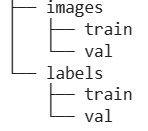

## Import required libraries

In [7]:
import glob
import os
import random
import shutil
from PIL import Image
import cv2
import matplotlib.pyplot as plt
import pandas as pd

## Re-organize source Dataset images/labels

Load all images and labels located inside the "CloudDataset" folder

In [2]:
# Set train, validate, and test dataset paths
train_dir_img = 'CloudDataset/train/images'
train_dir_lbl = 'CloudDataset/train/labels'

val_dir_img = 'CloudDataset/valid/images'
val_dir_lbl = 'CloudDataset/valid/labels'

In [3]:
import os

# Define source directory paths directly
train_dir_img = 'CloudDataset/train/images'
train_dir_lbl = 'CloudDataset/train/labels'

val_dir_img = 'CloudDataset/valid/images'
val_dir_lbl = 'CloudDataset/valid/labels'

test_dir_img = 'CloudDataset/test/images'
test_dir_lbl = 'CloudDataset/test/labels'

# Define directories to clean
dirs_to_clean = [
    (train_dir_img, train_dir_lbl),
    (val_dir_img, val_dir_lbl)
]

seen_bases = set()

for img_dir, lbl_dir in dirs_to_clean:
    if not os.path.exists(img_dir):
        print(f"Directory does not exist, skipping: {img_dir}")
        continue

    files = sorted(os.listdir(img_dir))

    removed_count = 0
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            # Roboflow export formats usually contain '.rf.' before the unique hash
            # e.g., 'Ac-N001_jpg.rf.8c98886d88bb955b60652b2a5f2f42a6.jpg' -> base 'Ac-N001_jpg'
            if '.rf.' in file:
                base_name = file.split('.rf.')[0]
            else:
                base_name = os.path.splitext(file)[0]

            img_path = os.path.join(img_dir, file)

            # Match corresponding label txt file
            label_file = os.path.splitext(file)[0] + '.txt'
            lbl_path = os.path.join(lbl_dir, label_file)

            if base_name in seen_bases:
                # Duplicate found, remove both image and label
                if os.path.exists(img_path):
                    os.remove(img_path)
                if os.path.exists(lbl_path):
                    os.remove(lbl_path)
                removed_count += 1
            else:
                # First instance, keep it
                seen_bases.add(base_name)

    print(f"Cleaned {img_dir}: Kept {len(seen_bases)} unique images, removed {removed_count} augmented instances.")

Directory does not exist, skipping: CloudDataset/train/images
Directory does not exist, skipping: CloudDataset/valid/images


Create new root folder called "All_data", with 2 child folders "images" and "labels"

In [4]:
os.makedirs('All_data/images')
os.makedirs('All_data/labels')

Copy the label txt files and image jpg files to the new folders created

In [30]:
#set the paths to labels and images directory for All data
label_dir= "All_data/labels"
image_dir= "All_data/images"

In [31]:
# Source directories mapped to their target categories
image_sources = [train_dir_img, val_dir_img]
label_sources = [train_dir_lbl, val_dir_lbl]

# Copy and process all images to image_dir
for src_dir in image_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                try:
                    img_path = os.path.join(src_dir, file)
                    image = Image.open(img_path)
                    image = image.convert("RGB")
                    base, ext = os.path.splitext(file)
                    # Replace '.' with '-' in the filename base
                    safe_base = base.replace(".", "-")
                    new_filename = safe_base + ".jpg"
                    image.save(os.path.join(image_dir, new_filename), "JPEG")
                except Exception as e:
                    print(f"Error processing image {file}: {e}")

# Copy all label files to label_dir
for src_dir in label_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith(".txt"):
                base, ext = os.path.splitext(file)
                # Replace '.' with '-' in the filename base
                safe_base = base.replace(".", "-")
                new_filename = safe_base + ext
                shutil.copy(os.path.join(src_dir, file), os.path.join(label_dir, new_filename))

NameError: name 'train_dir_img' is not defined

Take a look at the first 4 images in the "Final_data/images" folder to make sure the images are moved correctly

TypeError: Image data of dtype object cannot be converted to float

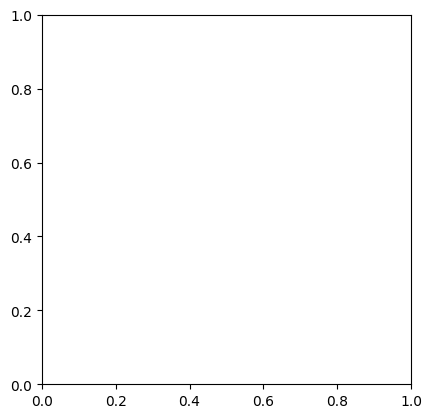

In [35]:
#visualize first four sample images from train data
for idx, image in enumerate(os.listdir(os.path.join(image_dir))):
    img = cv2.imread(os.path.join(image_dir, image), 1)
    plt.imshow(img)
    plt.show()

    if idx == 3:
        break

Check the Data balance

Series([], Name: count, dtype: int64)


IndexError: index 0 is out of bounds for axis 0 with size 0

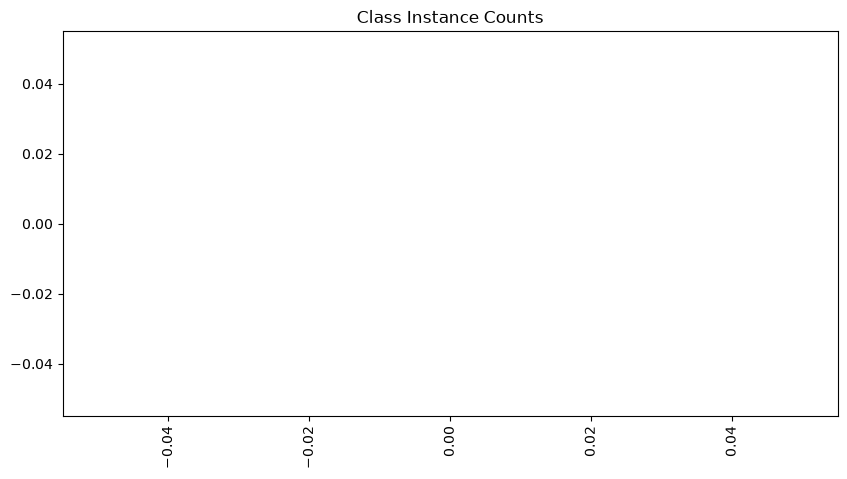

In [8]:
# 1. Define your class mapping dictionary
class_map = {
    0: "Altocumulus",
    1: "Altostratus",
    2: "Cirrocumulus",
    3: "Cirrostratus",
    4: "Cirrus",
    5: "Contrails",
    6: "Cumulonimbus",
    7: "Cumulus",
    8: "Nimbostratus",
    9: "Stratocumulus",
    10: "Stratus"
}

# 2. Gather label annotation files
labels_dir = "All_data/labels"
annotation_files = glob.glob(os.path.join(labels_dir, "*.txt"))

records = []
for file in annotation_files:
    with open(file, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                records.append(int(parts[0]))

# Create DataFrame
df = pd.DataFrame(records, columns=['class_id'])

# Map class IDs to names
df['class_name'] = df['class_id'].map(class_map)

# Value counts table
print(df['class_name'].value_counts())

# Plot distribution
df['class_name'].value_counts().plot(kind='bar', figsize=(10, 5), title="Class Instance Counts")
plt.xlabel("Cloud Class")
plt.ylabel("Number of Bounding Boxes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

30 images found


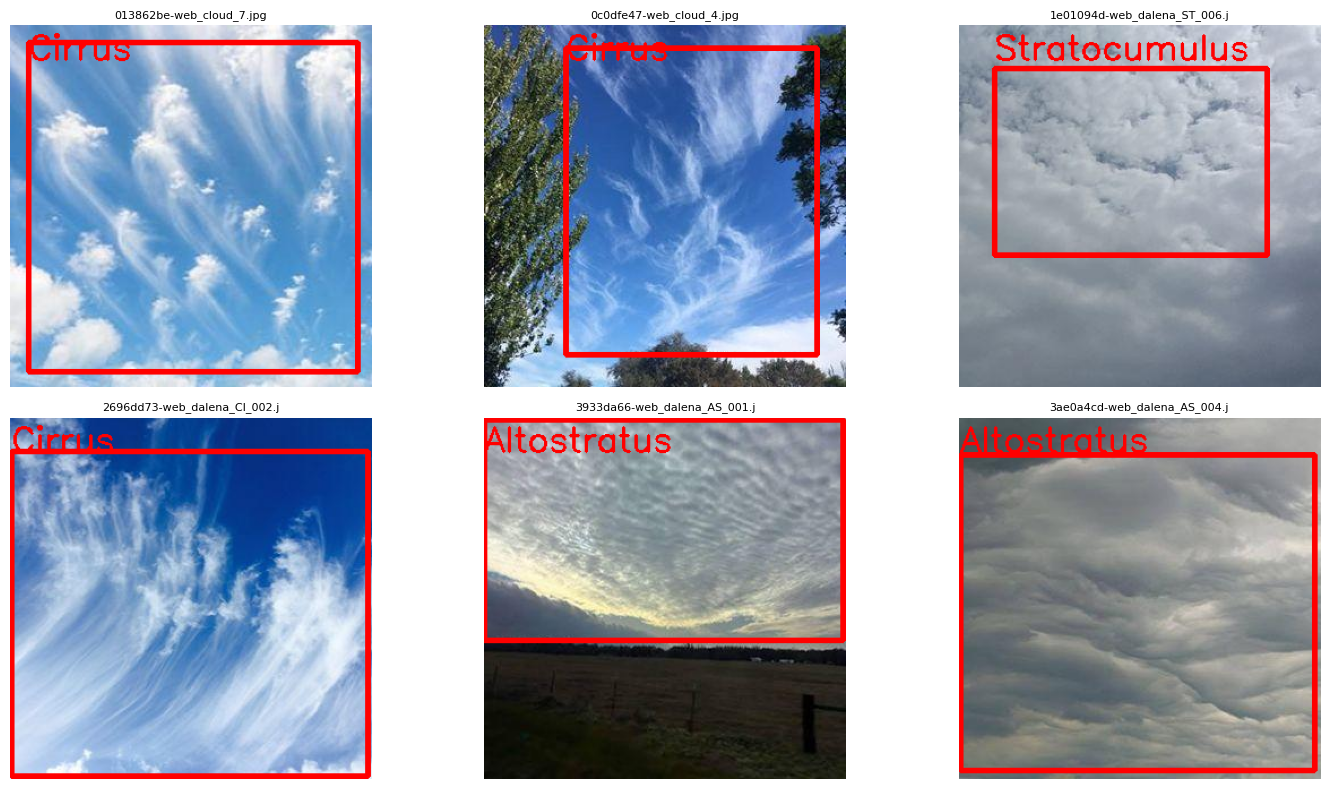

In [45]:
import os, cv2, matplotlib.pyplot as plt

class_map = {0:"Altocumulus",1:"Altostratus",2:"Cirrocumulus",3:"Cirrostratus",4:"Cirrus",
             5:"Contrails",6:"Cumulonimbus",7:"Cumulus",8:"Nimbostratus",9:"Stratocumulus",10:"Stratus"}

img_dir = "All_data/images/test"
lbl_dir = "All_data/labels/test"
who = "web"          # change to another name or "" to see everyone's

files = sorted(f for f in os.listdir(img_dir) if who in f.lower())
print(len(files), "images found")

def show(name):
    img = cv2.cvtColor(cv2.imread(os.path.join(img_dir, name)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lbl = os.path.join(lbl_dir, os.path.splitext(name)[0] + ".txt")
    if os.path.exists(lbl):
        for line in open(lbl):
            if not line.strip(): continue
            c, x, y, bw, bh = line.split()[:5]
            x, y, bw, bh = float(x)*w, float(y)*h, float(bw)*w, float(bh)*h
            p1, p2 = (int(x-bw/2), int(y-bh/2)), (int(x+bw/2), int(y+bh/2))
            cv2.rectangle(img, p1, p2, (255, 0, 0), max(3, w//300))
            cv2.putText(img, class_map[int(c)], (p1[0], max(p1[1]-10, 30)),
                        cv2.FONT_HERSHEY_SIMPLEX, max(1, w/1200), (255, 0, 0), max(2, w//500))
    return img

batch = files[:6]          # change to files[6:12], files[12:18] ... to page through
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, name in zip(axes.flat, batch):
    ax.imshow(show(name)); ax.set_title(name[:28], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

In [43]:
import os
files = sorted(os.listdir("All_data/images/test"))
d = [f for f in files if "dalena" in f.lower()]
m = [f for f in files if "marielle" in f.lower()]
other = [f for f in files if f not in d and f not in m]
print("dalena:", len(d), "| marielle:", len(m), "| other:", len(other))
for f in other:
    print(f)

dalena: 30 | marielle: 30 | other: 60
013862be-web_cloud_7.jpg
06a1f70f-cloud_25.jpg
07b16f4e-own_cloud_3.jpg
086eb905-own_cloud_6.jpg
0c0dfe47-web_cloud_4.jpg
15e2ed1a-cloud_11.jpg
18b5bc79-own_cloud_17.jpg
243168f7-cloud_9.jpg
25b8c45e-cloud_24.jpg
289535e4-cloud_10.jpg
2b1135d1-own_cloud_14.jpg
2b8a29b5-cloud_19.jpg
2c0172e3-cloud_20.jpg
2c8709f0-own_cloud_15.jpg
32e93ff5-cloud_23.jpg
3ce396fc-cloud_14.jpg
3ebb82aa-cloud_16.jpg
3f1345da-cloud_8.jpg
58a9876e-cloud_13.jpg
6ba7a8f9-own_cloud_21.jpg
6c00305a-cloud_28.jpg
6ef23e85-web_cloud_6.jpg
72abab26-cloud_26.jpg
7688ecb7-cloud_30.jpg
7a23e2fc-cloud_12.jpg
7ae0fcf9-own_cloud_20.jpg
7f776872-web_cloud_3.jpg
8767d7ba-web_cloud_1.jpg
8c9c2c57-own_cloud_13.jpg
932d1792-own_cloud_12.jpg
9b0fdf21-web_cloud_9.jpg
a7b1239a-own_cloud_9.jpg
a82d2775-cloud_15.jpg
aacf9900-cloud_17.jpg
aad65f27-own_cloud_16.jpg
afb6d43f-cloud_27.jpg
c1e98506-cloud_7.jpg
c28d1616-own_cloud_5.jpg
c2dcf207-cloud_18.jpg
c87a1d04-own_cloud_4.jpg
c91dd116-own_cloud_2

## Split the source data
Split into 80-20 train-validation sets and re-organize the data into correct sub-folders

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Load the sorted lists of all images and matching labels
# Sorting ensures that images and labels pair up correctly (e.g., image[i] matches label[i])
images_dir = "All_data/images"
labels_dir = "All_data/labels"

# Get all file names and sort them alphabetically
image_files = sorted(os.listdir(images_dir))
label_files = sorted(os.listdir(labels_dir))

# Double check we are matching base names (e.g., image_01.jpg maps to image_01.txt)
# We'll filter to make sure we only split perfectly matching image-label pairs
valid_images = []
valid_labels = []

for img in image_files:
    base_name = os.path.splitext(img)[0]
    label_name = f"{base_name}.txt"
    if label_name in label_files:
        valid_images.append(os.path.join(images_dir, img))
        valid_labels.append(os.path.join(labels_dir, label_name))

# 2. Split into 80% train+validation and 20% test set
X_train, X_validation, y_train, y_validation = train_test_split(
    valid_images,
    valid_labels,
    test_size=0.20,
    random_state=42
)

print(f"Split completed:")
print(f"  - Train set size: {len(X_train)} pairs")
print(f"  - Validation set size: {len(X_validation)} pairs")


Split completed:
  - Train set size: 2016 pairs
  - Validation set size: 505 pairs


In [ ]:
# Define the target subdirectories
splits = ['train', 'val']
for split in splits:
    os.makedirs(os.path.join("All_data/images", split), exist_ok=True)
    os.makedirs(os.path.join("All_data/labels", split), exist_ok=True)

# Helper function to move a list of files to their respective folder
def move_files(file_paths, destination_folder):
    for path in file_paths:
        if os.path.exists(path):
            filename = os.path.basename(path)
            shutil.move(path, os.path.join(destination_folder, filename))

# Move image sets
move_files(X_train, "All_data/images/train")
move_files(X_validation, "All_data/images/val")

# Move label sets
move_files(y_train, "All_data/labels/train")
move_files(y_validation, "All_data/labels/val")

# Verify counts in new structured folders
print("\nPhysical Split Verification:")
for split in splits:
    img_count = len(os.listdir(os.path.join("All_data/images", split)))
    lbl_count = len(os.listdir(os.path.join("All_data/labels", split)))
    print(f"  - {split.capitalize()} Set: {img_count} images | {lbl_count} labels")



Physical Split Verification:
  - Train Set: 2016 images | 2016 labels
  - Val Set: 505 images | 505 labels


## Organize group member images and Move them into test folder as test set

Download the images collected from all 4 group members ([FirstName]_Cloud_Data_Labeled) located in this link https://1sfu-my.sharepoint.com/:f:/r/personal/yya6_sfu_ca/Documents/CV%20Project%20Group%2013?d=w11d6cbb929af48b29ee060bcf9c1bf78&csf=1&web=1&e=WJnLSs


In [9]:
# creates Members_Dataset and moves every folder ending in _CloudData_Labeled
import os, shutil

os.makedirs("Members_Dataset", exist_ok=True)

for name in os.listdir("."):
    if name.endswith("_CloudData_Labeled") and os.path.isdir(name):
        shutil.move(name, os.path.join("Members_Dataset", name))
        print("moved", name)

# show what's inside so you can check the structure
for name in os.listdir("Members_Dataset"):
    print(name, "->", os.listdir(os.path.join("Members_Dataset", name)))

Dalena_CloudData_Labeled -> ['classes.txt', 'images', 'labels', 'notes.json']
Marielle_CloudData_Labeled -> ['classes.txt', 'images', 'labels', 'notes.json']
Eugene_CloudData_Labeled -> ['classes.txt', '.DS_Store', 'images', 'labels']
Martina_CloudData_Labeled -> ['classes.txt', 'images', 'labels', 'notes.json']


In [10]:
# Set all paths to the dataset
eugene_dir_img = 'Members_Dataset/Eugene_CloudData_Labeled/images'
eugene_dir_lbl = 'Members_Dataset/Eugene_CloudData_Labeled/labels'

dalena_dir_img = 'Members_Dataset/Dalena_CloudData_Labeled/images'
dalena_dir_lbl = 'Members_Dataset/Dalena_CloudData_Labeled/labels'

martina_dir_img = 'Members_Dataset/Martina_CloudData_Labeled/images'
martina_dir_lbl = 'Members_Dataset/Martina_CloudData_Labeled/labels'

marielle_dir_img = 'Members_Dataset/Marielle_CloudData_Labeled/images'
marielle_dir_lbl = 'Members_Dataset/Marielle_CloudData_Labeled/labels'

Copy the label txt files and image jpg files to the new folders created

In [11]:
#set the paths to labels and images directory for test data
test_label_dir= "All_data/labels/test"
test_image_dir= "All_data/images/test"

os.makedirs(os.path.join("All_data/labels/test"), exist_ok=True)
os.makedirs(os.path.join("All_data/images/test"), exist_ok=True)

Every image from every member gets converted to RGB .jpg and saved into All_data/images/test. Every label .txt from every member gets copied into All_data/labels/test

In [12]:
# Source directories mapped to their target categories
image_sources = [eugene_dir_img, dalena_dir_img, martina_dir_img, marielle_dir_img]
label_sources = [eugene_dir_lbl, dalena_dir_lbl, martina_dir_lbl, marielle_dir_lbl]

# Copy and process all images to test_image_dir
for src_dir in image_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                try:
                    img_path = os.path.join(src_dir, file)
                    image = Image.open(img_path)
                    image = image.convert("RGB")
                    new_filename = os.path.splitext(file)[0] + ".jpg"
                    image.save(os.path.join(test_image_dir, new_filename), "JPEG")
                except Exception as e:
                    print(f"Error processing image {file}: {e}")

# Copy all label files to test_label_dir
for src_dir in label_sources:
    if os.path.exists(src_dir):
        for file in os.listdir(src_dir):
            if file.lower().endswith(".txt"):
                shutil.copy(os.path.join(src_dir, file), os.path.join(test_label_dir, file))

## Check for missing files

Each set should contain the same amount of images and labels

In [1]:
train_img = "All_data/images/train"
train_lbl = "All_data/labels/train"
val_img = "All_data/images/val"
val_lbl = "All_data/labels/val"
test_img = "All_data/images/test"
test_lbl = "All_data/labels/test"

# Group the folder pairs together for verification
pairs = [
    ("Train Set", train_img, train_lbl),
    ("Validation Set", val_img, val_lbl),
    ("Test Set", test_img, test_lbl)
]

for name, img_folder, lbl_folder in pairs:
    num_images = len([f for f in os.listdir(img_folder) if os.path.isfile(os.path.join(img_folder, f))])
    num_labels = len([f for f in os.listdir(lbl_folder) if os.path.isfile(os.path.join(lbl_folder, f))])
    print(f"{name}: {num_images} images | {num_labels} labels")
    assert num_images == num_labels, f"Mismatch in {name}! Images: {num_images}, Labels: {num_labels}"

NameError: name 'os' is not defined

visualization graph for data


train: 2016 images (76.3%)
val: 505 images (19.1%)
test: 120 images (4.5%)
Total: 2641


,train,val,test
Altocumulus,179,40,19
Altostratus,156,32,11
Cirrocumulus,211,49,0
Cirrostratus,229,59,2
Cirrus,118,22,35
Contrails,164,41,3
Cumulonimbus,180,55,1
Cumulus,134,44,61
Nimbostratus,216,58,4
Stratocumulus,274,70,52


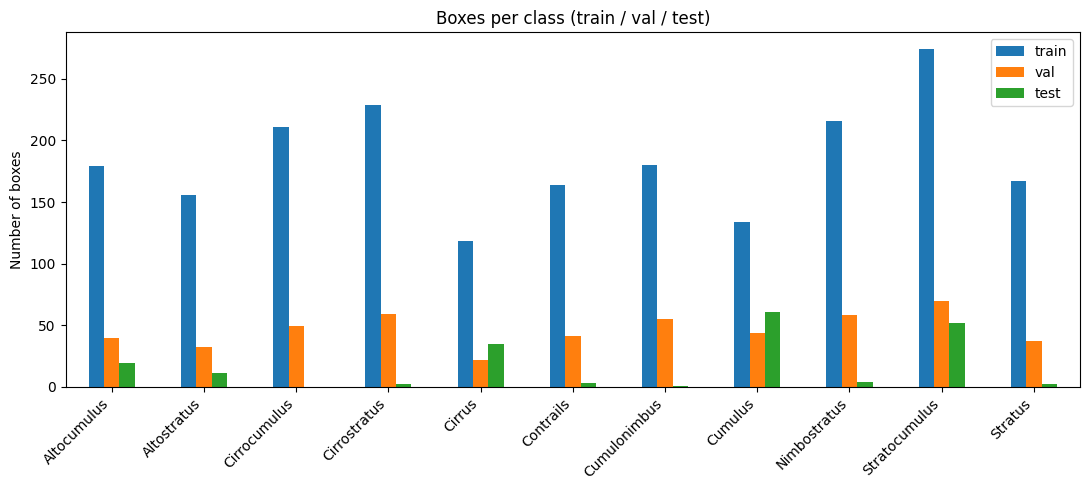

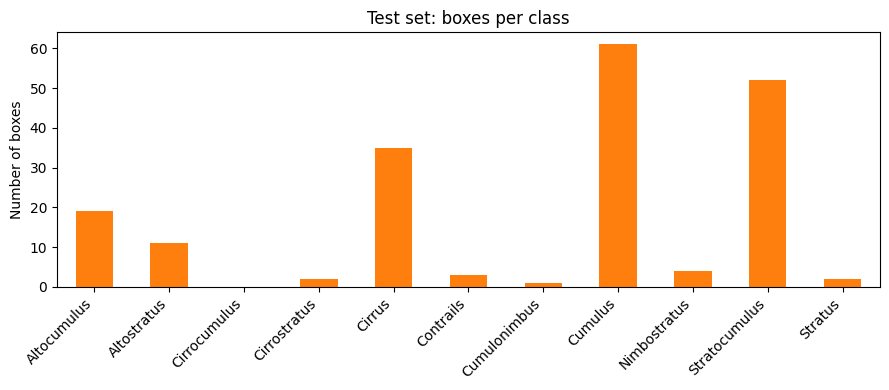

In [34]:
import glob, pandas as pd, matplotlib.pyplot as plt

class_map = {0:"Altocumulus",1:"Altostratus",2:"Cirrocumulus",3:"Cirrostratus",4:"Cirrus",
             5:"Contrails",6:"Cumulonimbus",7:"Cumulus",8:"Nimbostratus",9:"Stratocumulus",10:"Stratus"}

# --- split percentages ---
n_img = {s: len(glob.glob(f"All_data/images/{s}/*.jpg")) for s in ["train","val","test"]}
total = sum(n_img.values())
for s, n in n_img.items():
    print(f"{s}: {n} images ({n/total:.1%})")
print("Total:", total)

# --- boxes per class per split ---
counts = {}
for s in ["train","val","test"]:
    ids = []
    for f in glob.glob(f"All_data/labels/{s}/*.txt"):
        ids += [int(l.split()[0]) for l in open(f) if l.strip()]
    counts[s] = pd.Series(ids).map(class_map).value_counts()
df = pd.DataFrame(counts).reindex(class_map.values()).fillna(0).astype(int)
display(df)

# Graph 1: all splits together
df.plot(kind="bar", figsize=(11,5), title="Boxes per class (train / val / test)")
plt.ylabel("Number of boxes"); plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig("class_distribution.png", dpi=200); plt.show()

# Graph 2: test set alone (so its imbalance is visible)
df["test"].plot(kind="bar", figsize=(9,4), color="tab:orange", title="Test set: boxes per class")
plt.ylabel("Number of boxes"); plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig("class_distribution_test.png", dpi=200); plt.show()

Randomly pick an image and a label from each set to check if annotation can be populated

Visualizing from train set: Ac-N130_jpg-rf-0210ab888ac4303e89495a3d99262bde.jpg


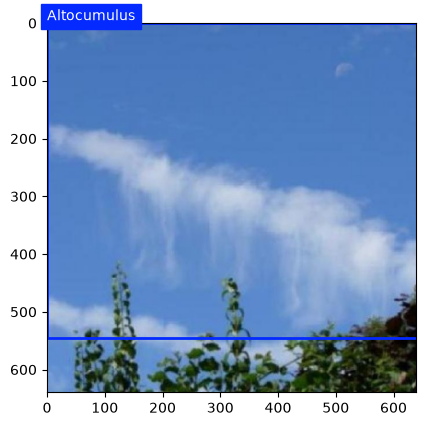

Visualizing from val set: Ct-N196_jpg-rf-1e61c589c9ed603081a9f328540caee7.jpg


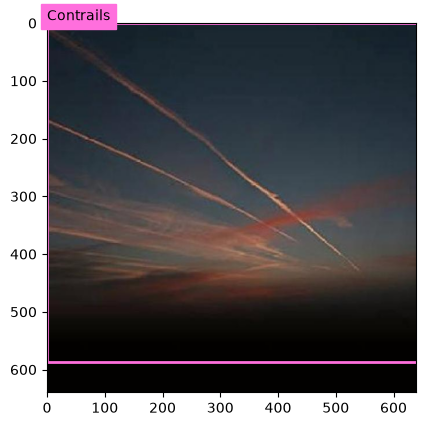

Visualizing from test set: e9dd9ad0-own_marielle_02.jpg


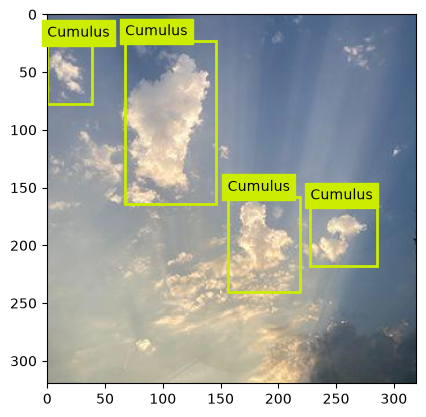

In [ ]:
from ultralytics.data.utils import visualize_image_annotations
# define the class map
class_map = {
    0: "Altocumulus",
    1: "Altostratus",
    2: "Cirrocumulus",
    3: "Cirrostratus",
    4: "Cirrus",
    5: "Contrails",
    6: "Cumulonimbus",
    7: "Cumulus",
    8: "Nimbostratus",
    9: "Stratocumulus",
    10: "Stratus"
}

# Splits to choose from
splits = ["train", "val", "test"]

for split in splits:
    img_dir = f"All_data/images/{split}"
    lbl_dir = f"All_data/labels/{split}"

    if os.path.exists(img_dir) and os.path.exists(lbl_dir):
        # Get a list of all image files in this split
        image_files = [f for f in os.listdir(img_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]

        if image_files:
            # Pick 1 random image from this split
            random_image = random.choice(image_files)

            # Construct matching image and label paths
            base_name = os.path.splitext(random_image)[0]
            random_image_path = os.path.join(img_dir, random_image)
            random_label_path = os.path.join(lbl_dir, f"{base_name}.txt")

            # Visualize
            print(f"Visualizing from {split} set: {random_image}")
            visualize_image_annotations(
                random_image_path,
                random_label_path,
                class_map,
            )
        else:
            print(f"No images found in {img_dir}")
    else:
        print(f"Directory does not exist for split: {split}")

# Model Training

In [2]:
%pip install ultralytics
import ultralytics

ultralytics.checks()

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


In [3]:
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/IAT 360/All_data.zip"
extract_path = "/content/drive/MyDrive/IAT 360/"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete!")

Extraction complete!


In [14]:
%cd "/content/drive/MyDrive/IAT 360"
%pwd
%ls

[Errno 2] No such file or directory: '/content/drive/MyDrive/IAT 360'
/content/drive/MyDrive/IAT360
All_data/  runs/


In [16]:
%%writefile config.yaml
path: All_data
train: images/train
val: images/val
test: images/test

# Classes
nc: 11 # replace based on your dataset's number of classes

# Class names
names:
    0: Altocumulus
    1: Altostratus
    2: Cirrocumulus
    3: Cirrostratus
    4: Cirrus
    5: Contrails
    6: Cumulonimbus
    7: Cumulus
    8: Nimbostratus
    9: Stratocumulus
    10: Stratus


Writing config.yaml


In [21]:
from ultralytics import YOLO

model = YOLO('yolov8s.pt')

In [ ]:
# Train using config.yaml and store results inside your Google Drive directory
model.train(
    data="config.yaml",
    epochs=50,                                                    # 50 epochs is a good baseline length
    patience=10,                                                  # Increased from 5 to 10 to avoid premature early stopping
    batch=16,                                                     # Standard batch size for 16GB GPU VRAM
    device=0,                                                     # Force training on the GPU (Tesla T4)
    project="/content/drive/MyDrive/IAT 360/runs",                 # Keep runs organized inside your Drive
    name="cloud_baseline_result_yolov8s"                         # Specific subfolder for this run
)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=config.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cloud_baseline_result_yolov8s, nbs=64, nms=None, opset=None, optimize=False, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b4074c66430>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.

In [ ]:
!find /root /content -name "*.pt"

/content/drive/MyDrive/IAT 360/yolov8s.pt
/content/drive/MyDrive/IAT 360/runs/cloud_baseline_result_yolov8s/weights/last.pt
/content/drive/MyDrive/IAT 360/runs/cloud_baseline_result_yolov8s/weights/best.pt
/content/drive/MyDrive/custom_folder/train/weights/last.pt
/content/drive/MyDrive/custom_folder/train/weights/best.pt
/content/drive/MyDrive/best.pt


## Hyperparameter Evaluation


Make sure you download both of the following files and unzip it to your google drive
* [All_data](https://1sfu-my.sharepoint.com/:u:/r/personal/yya6_sfu_ca/Documents/CV%20Project%20Group%2013/All_data.zip?d=w99f0d6e24789462aa37f4e1b3fae6704&csf=1&web=1&e=5w1wHF)
* [runs](https://1sfu-my.sharepoint.com/:u:/r/personal/yya6_sfu_ca/Documents/CV%20Project%20Group%2013/runs-20261106T030510Z-1-001.zip?d=w74339fa9a015476e8e23f2bc48ba9367&csf=1&web=1&e=ZKJmJJ)

Connect to your Google Drive to load the project files

In [1]:
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


Set your current path to inside the Project folder containing the following:
* The baseline weight located inside `runs/cloud_baseline_result_yolov8s/weights/best.pt` path
* The `All_data` dataset folder
* The config.yaml file (if you don't have this created on your Google Drive, create it using the %%writefile config.yaml
 cell above under the Model Training section)

In [3]:
# Ensure you have the correct file structure inside this path
%cd "/content/drive/MyDrive/IAT360"
import os

# Files to verify
files_to_check = [
    'runs/cloud_baseline_result_yolov8s/weights/best.pt',
    'config.yaml',
    'All_data',
    'All_data/images',
    'All_data/labels'
]

print("=== File Verification Results ===")
for path in files_to_check:
    exists = os.path.exists(path)
    status = "✅ FOUND" if exists else "❌ MISSING"
    print(f"{path:<50} : {status}")

/content/drive/MyDrive/IAT360
=== File Verification Results ===
runs/cloud_baseline_result_yolov8s/weights/best.pt : ✅ FOUND
config.yaml                                        : ✅ FOUND
All_data                                           : ✅ FOUND
All_data/images                                    : ✅ FOUND
All_data/labels                                    : ✅ FOUND


Validation

In [23]:
import pandas as pd
from ultralytics import YOLO

# (optimizer, lr0). AdamW is the control, the rest are your 3 values
opt_values = [("AdamW", 0.000667), ("SGD", 0.01), ("Adam", 0.000667), ("RMSProp", 0.000667)]
results_list = []

for opt, lr in opt_values:
    print(f"\n{'='*50}\nTraining with optimizer = {opt}, lr0 = {lr}\n{'='*50}")
    model = YOLO('yolov8s.pt')       # same starting point for every run
    model.train(
        data="config.yaml",
        epochs=15, patience=10, batch=16, imgsz=640, device=0,   # 15 epochs, rest same as baseline
        optimizer=opt, lr0=lr,
        project="/content/drive/MyDrive/IAT360/runs",
        name=f"opt15_{opt}",
        verbose=False
    )
    metrics = YOLO(model.trainer.best).val(data="config.yaml", split="val", verbose=False)
    results_list.append({
        "Optimizer": opt,
        "Precision": round(metrics.box.mp, 4),
        "Recall": round(metrics.box.mr, 4),
        "mAP50": round(metrics.box.map50, 4),
        "mAP50-95": round(metrics.box.map, 4),
    })

df_results = pd.DataFrame(results_list)
df_results.to_csv("/content/drive/MyDrive/IAT360/optimizer_results_15ep.csv", index=False)
display(df_results)
display(pd.DataFrame(results_list))


Training with optimizer = AdamW, lr0 = 0.000667
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=config.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.000667, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=opt15_AdamW, nbs=64, nms

,Optimizer,Precision,Recall,mAP50,mAP50-95
0,AdamW,0.3864,0.6390,0.4716,0.3994
1,SGD,0.3700,0.5309,0.4440,0.3838
2,Adam,0.3920,0.5791,0.4825,0.4247
3,RMSProp,0.1290,0.7791,0.1916,0.1639


,Optimizer,Precision,Recall,mAP50,mAP50-95
0,AdamW,0.3864,0.6390,0.4716,0.3994
1,SGD,0.3700,0.5309,0.4440,0.3838
2,Adam,0.3920,0.5791,0.4825,0.4247
3,RMSProp,0.1290,0.7791,0.1916,0.1639


#Hyperparmeter Result Metrics

Results from best to worst on validation:


In [24]:
best = df_results[df_results["Optimizer"] != "AdamW"].sort_values("mAP50", ascending=False).iloc[0]
print("Winner (excluding the AdamW control):", best["Optimizer"])
display(df_results.sort_values("mAP50", ascending=False))

Winner (excluding the AdamW control): Adam


,Optimizer,Precision,Recall,mAP50,mAP50-95
2,Adam,0.3920,0.5791,0.4825,0.4247
0,AdamW,0.3864,0.6390,0.4716,0.3994
1,SGD,0.3700,0.5309,0.4440,0.3838
3,RMSProp,0.1290,0.7791,0.1916,0.1639


Test-set evaluation cell to compare the results


In [25]:
from ultralytics import YOLO
import pandas as pd

base = "runs/"
runs = {
    "Baseline (AdamW, 50 ep)": base + "cloud_baseline_result_yolov8s/weights/best.pt",
    "AdamW (15 ep)":   base + "opt15_AdamW/weights/best.pt",
    "SGD (15 ep)":     base + "opt15_SGD/weights/best.pt",
    "Adam (15 ep)":    base + "opt15_Adam/weights/best.pt",
    "RMSProp (15 ep)": base + "opt15_RMSProp/weights/best.pt",
}

rows = []
for name, path in runs.items():
    m = YOLO(path).val(data="config.yaml", split="test", verbose=False)
    rows.append({"Model": name,
                 "Precision": round(m.box.mp, 4), "Recall": round(m.box.mr, 4),
                 "mAP50": round(m.box.map50, 4), "mAP50-95": round(m.box.map, 4)})

df_test = pd.DataFrame(rows).sort_values("mAP50", ascending=False)
df_test.to_csv("optimizer_results_test.csv", index=False)
display(df_test)

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.2 ms, read: 0.9±2.1 MB/s, size: 8.8 KB)
val: Scanning /content/drive/MyDrive/IAT360/All_data/labels/test... 120 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 1.3it/s 1:34
val: New cache created: /content/drive/MyDrive/IAT360/All_data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.7it/s 2.9s
                   all        120        190      0.359      0.185      0.111     0.0558
Speed: 2.3ms preprocess, 10.2ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/drive/MyDrive/IAT360/runs/detect/val-5
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
va

,Model,Precision,Recall,mAP50,mAP50-95
2,SGD (15 ep),0.1299,0.2346,0.1125,0.0601
1,AdamW (15 ep),0.1418,0.2626,0.1123,0.0538
0,"Baseline (AdamW, 50 ep)",0.3585,0.1848,0.1110,0.0558
3,Adam (15 ep),0.1195,0.2783,0.0974,0.0508
4,RMSProp (15 ep),0.0897,0.3389,0.0843,0.0442


Both of them together:

In [4]:
from ultralytics import YOLO
import numpy as np, pandas as pd

runs = {
    "Baseline (AdamW, 50 ep)": "runs/cloud_baseline_result_yolov8s/weights/best.pt",
    "AdamW (15 ep)":   "runs/opt15_AdamW/weights/best.pt",
    "SGD (15 ep)":     "runs/opt15_SGD/weights/best.pt",
    "Adam (15 ep)":    "runs/opt15_Adam/weights/best.pt",
    "RMSProp (15 ep)": "runs/opt15_RMSProp/weights/best.pt",
}

rows = []
for label, path in runs.items():
    m = YOLO(path)
    nc = len(m.names)
    for split in ["val", "test"]:
        r = m.val(data="config.yaml", split=split, verbose=False, plots=True)
        p, rc = r.box.mp, r.box.mr
        cm = r.confusion_matrix.matrix
        acc = np.trace(cm[:nc, :nc]) / cm[:, :nc].sum()
        rows.append({"model": label, "split": split,
                     "precision": round(p, 3), "recall": round(rc, 3),
                     "F1": round(2 * p * rc / (p + rc + 1e-9), 3),
                     "accuracy": round(acc, 3),
                     "mAP50": round(r.box.map50, 3), "mAP50-95": round(r.box.map, 3)})

df_all = pd.DataFrame(rows)
df_all.to_csv("final_results.csv", index=False)
display(df_all)

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.2 ms, read: 0.0±0.0 MB/s, size: 31.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/IAT360/All_data/labels/val.cache... 505 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 505/505 81.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 2.0it/s 16.0s
                   all        505        507      0.439      0.607      0.536      0.468
Speed: 2.0ms preprocess, 9.6ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved to /content/drive/MyDrive/IAT360/runs/detect/val-24
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)

,model,split,precision,recall,F1,accuracy,mAP50,mAP50-95
0,"Baseline (AdamW, 50 ep)",val,0.439,0.607,0.509,0.535,0.536,0.468
1,"Baseline (AdamW, 50 ep)",test,0.359,0.185,0.244,0.189,0.111,0.056
2,AdamW (15 ep),val,0.386,0.639,0.482,0.521,0.472,0.399
3,AdamW (15 ep),test,0.142,0.263,0.184,0.153,0.112,0.054
4,SGD (15 ep),val,0.370,0.531,0.436,0.462,0.444,0.384
5,SGD (15 ep),test,0.130,0.235,0.167,0.132,0.112,0.060
6,Adam (15 ep),val,0.392,0.579,0.468,0.497,0.483,0.425
7,Adam (15 ep),test,0.119,0.278,0.167,0.137,0.097,0.051
8,RMSProp (15 ep),val,0.129,0.779,0.221,0.245,0.192,0.164
9,RMSProp (15 ep),test,0.090,0.339,0.142,0.158,0.084,0.044


Optimizer results in a table

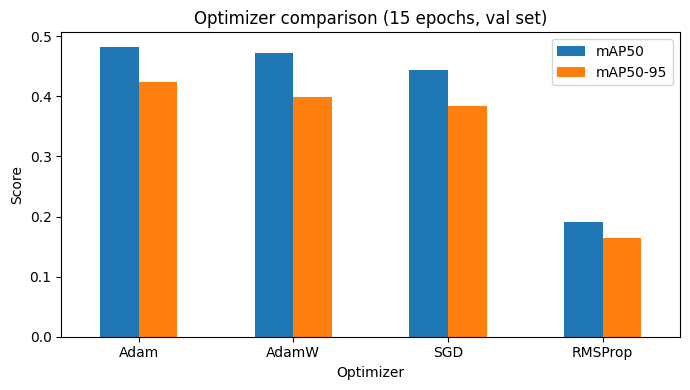

In [26]:
import matplotlib.pyplot as plt

df = df_results.sort_values("mAP50", ascending=False)
ax = df.plot(x="Optimizer", y=["mAP50", "mAP50-95"], kind="bar", figsize=(7,4))
ax.set_ylabel("Score")
ax.set_title("Optimizer comparison (15 epochs, val set)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("optimizer_comparison.png", dpi=200)
plt.show()

# Hyperparmeter Result Metrics

new run


In [5]:
from ultralytics import YOLO
import numpy as np, pandas as pd

runs = {
    "Baseline (AdamW, 50 ep)": "runs/cloud_baseline_result_yolov8s/weights/best.pt",
    "AdamW (15 ep)":   "runs/opt15_AdamW/weights/best.pt",
    "SGD (15 ep)":     "runs/opt15_SGD/weights/best.pt",
    "Adam (15 ep)":    "runs/opt15_Adam/weights/best.pt",
    "RMSProp (15 ep)": "runs/opt15_RMSProp/weights/best.pt",
}

def evaluate(split):
    rows = []
    for name, path in runs.items():
        m = YOLO(path)
        nc = len(m.names)
        r = m.val(data="config.yaml", split=split, verbose=False, plots=True)
        p, rc = r.box.mp, r.box.mr
        cm = r.confusion_matrix.matrix        # rows = predicted, cols = true, last = background
        acc = np.trace(cm[:nc, :nc]) / cm[:, :nc].sum()
        rows.append({"Model": name, "Precision": round(p, 3), "Recall": round(rc, 3),
                     "F1": round(2 * p * rc / (p + rc + 1e-9), 3), "Accuracy": round(acc, 3),
                     "mAP50": round(r.box.map50, 3), "mAP50-95": round(r.box.map, 3)})
    return pd.DataFrame(rows)

df_val = evaluate("val");   print("VALIDATION"); display(df_val);  df_val.to_csv("final_val.csv", index=False)
df_test = evaluate("test"); print("TEST");       display(df_test); df_test.to_csv("final_test.csv", index=False)

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 30.7±12.1 MB/s, size: 26.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/IAT360/All_data/labels/val.cache... 505 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 505/505 88.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 3.8it/s 8.3s
                   all        505        507      0.439      0.607      0.536      0.468
Speed: 1.3ms preprocess, 9.1ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /content/drive/MyDrive/IAT360/runs/detect/val-34
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB

,Model,Precision,Recall,F1,Accuracy,mAP50,mAP50-95
0,"Baseline (AdamW, 50 ep)",0.439,0.607,0.509,0.535,0.536,0.468
1,AdamW (15 ep),0.386,0.639,0.482,0.521,0.472,0.399
2,SGD (15 ep),0.370,0.531,0.436,0.462,0.444,0.384
3,Adam (15 ep),0.392,0.579,0.468,0.497,0.483,0.425
4,RMSProp (15 ep),0.129,0.779,0.221,0.245,0.192,0.164


Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 20.4±13.4 MB/s, size: 18.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/IAT360/All_data/labels/test.cache... 120 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 22.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.1it/s 7.5s
                   all        120        190      0.359      0.185      0.111     0.0558
Speed: 6.4ms preprocess, 11.4ms inference, 0.0ms loss, 11.9ms postprocess per image
Results saved to /content/drive/MyDrive/IAT360/runs/detect/val-39
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913Mi

,Model,Precision,Recall,F1,Accuracy,mAP50,mAP50-95
0,"Baseline (AdamW, 50 ep)",0.359,0.185,0.244,0.189,0.111,0.056
1,AdamW (15 ep),0.142,0.263,0.184,0.153,0.112,0.054
2,SGD (15 ep),0.130,0.235,0.167,0.132,0.112,0.060
3,Adam (15 ep),0.119,0.278,0.167,0.137,0.097,0.051
4,RMSProp (15 ep),0.090,0.339,0.142,0.158,0.084,0.044


Loss curve

Shows how wrong the model is at each epoch of training

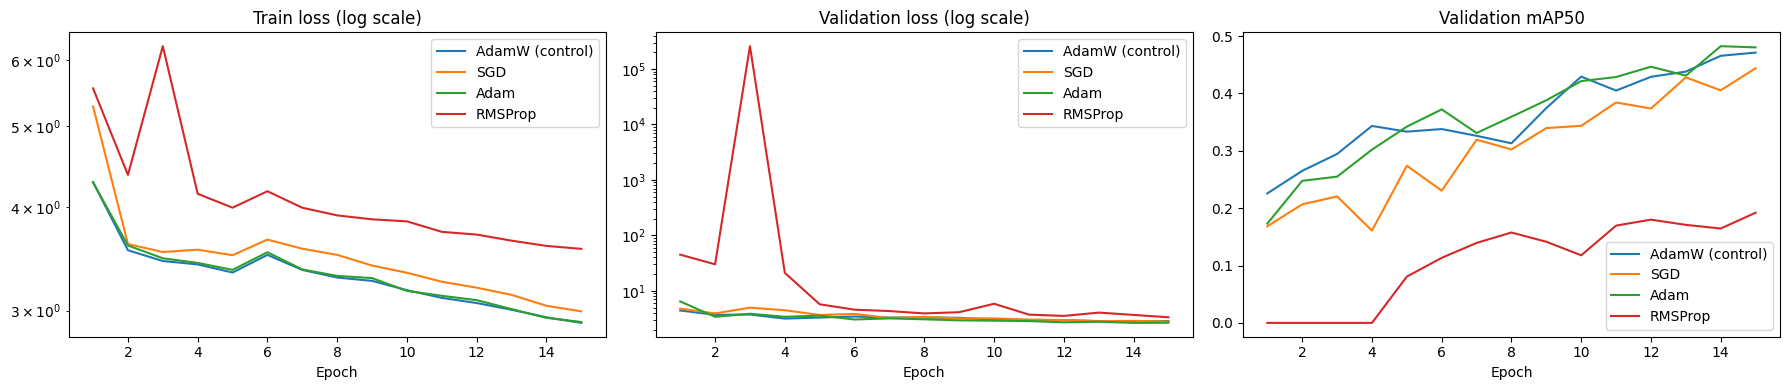

In [6]:
import pandas as pd, matplotlib.pyplot as plt

folders = {"AdamW (control)":"opt15_AdamW", "SGD":"opt15_SGD", "Adam":"opt15_Adam", "RMSProp":"opt15_RMSProp"}
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for label, f in folders.items():
    d = pd.read_csv(f"runs/{f}/results.csv"); d.columns = d.columns.str.strip()
    ax[0].plot(d["epoch"], d["train/box_loss"]+d["train/cls_loss"]+d["train/dfl_loss"], label=label)
    ax[1].plot(d["epoch"], d["val/box_loss"]+d["val/cls_loss"]+d["val/dfl_loss"], label=label)
    ax[2].plot(d["epoch"], d["metrics/mAP50(B)"], label=label)
ax[0].set_yscale("log"); ax[1].set_yscale("log")
for a, t in zip(ax, ["Train loss (log scale)", "Validation loss (log scale)", "Validation mAP50"]):
    a.set_title(t); a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.savefig("loss_curves.png", dpi=200); plt.show()